In [1]:
"""
Comprehensive EDA for Polish Companies Bankruptcy Dataset (2-year)
- Missingness analysis
- Distributions & summary statistics
- Outlier detection
- Correlation analysis
- Class imbalance & target relationships
- Additional useful diagnostics
"""
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ============================================================
# 1. LOAD & BASIC INFO
# ============================================================
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(),".."))
DATA_PATH = os.path.join(PROJECT_ROOT, 'data','processed','bankruptcy_2yr.csv')  # adjust path if needed

df = pd.read_csv(DATA_PATH)
print("="*70)
print("DATASET OVERVIEW")
print("="*70)
print(f"Shape: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"\nColumn types:\n{df.dtypes.value_counts()}")
print(f"\nFirst 5 rows:\n{df.head()}")
print(f"\nTarget distribution (class):\n{df['class'].value_counts()}")
print(f"Class imbalance ratio (0:1): {df['class'].value_counts()[0] / df['class'].value_counts()[1]:.2f}:1")



DATASET OVERVIEW
Shape: (9792, 65)
Memory usage: 4.86 MB

Column types:
float64    64
int64       1
Name: count, dtype: int64

First 5 rows:
         A1       A2       A3      A4       A5        A6        A7       A8  \
0  0.159290  0.46240  0.07773  1.1683  -44.853  0.467020  0.189480  0.82895   
1 -0.127430  0.46243  0.26917  1.7517    7.597  0.000925 -0.127430  1.16250   
2  0.070488  0.23570  0.52781  3.2393  125.680  0.163670  0.086895  2.87180   
3  0.136760  0.40538  0.31543  1.8705   19.115  0.504970  0.136760  1.45390   
4 -0.110080  0.69793  0.18878  1.2713  -15.344  0.000000 -0.110080  0.43282   

       A9      A10  ...       A56      A57      A58       A59      A60  \
0  1.1223  0.38330  ...  0.108990  0.41557  0.89101  0.001422   7.7928   
1  1.2944  0.53757  ... -0.089372 -0.23704  1.06250  0.150410   5.4327   
2  1.0574  0.67689  ...  0.054286  0.10413  0.94571  0.000000   7.1070   
3  1.1144  0.58938  ...  0.102630  0.23203  0.89737  0.073024   6.1384   
4  1.7350  0.3


MISSINGNESS ANALYSIS

Columns with missing values (sorted by % missing):
     missing_count  missing_pct
A37           4442        45.36
A27            641         6.55
A60            614         6.27
A45            613         6.26
A53            231         2.36
A64            231         2.36
A28            231         2.36
A54            231         2.36
A24            211         2.15
A41            187         1.91
A21            158         1.61
A32             96         0.98
A52             76         0.78
A47             73         0.75
A46             43         0.44
A33             43         0.44
A4              43         0.44
A40             43         0.44
A63             43         0.44
A12             43         0.44
A61             32         0.33
A43             21         0.21
A39             21         0.21
A44             21         0.21
A42             21         0.21
A19             21         0.21
A20             21         0.21
A13             21         0.2

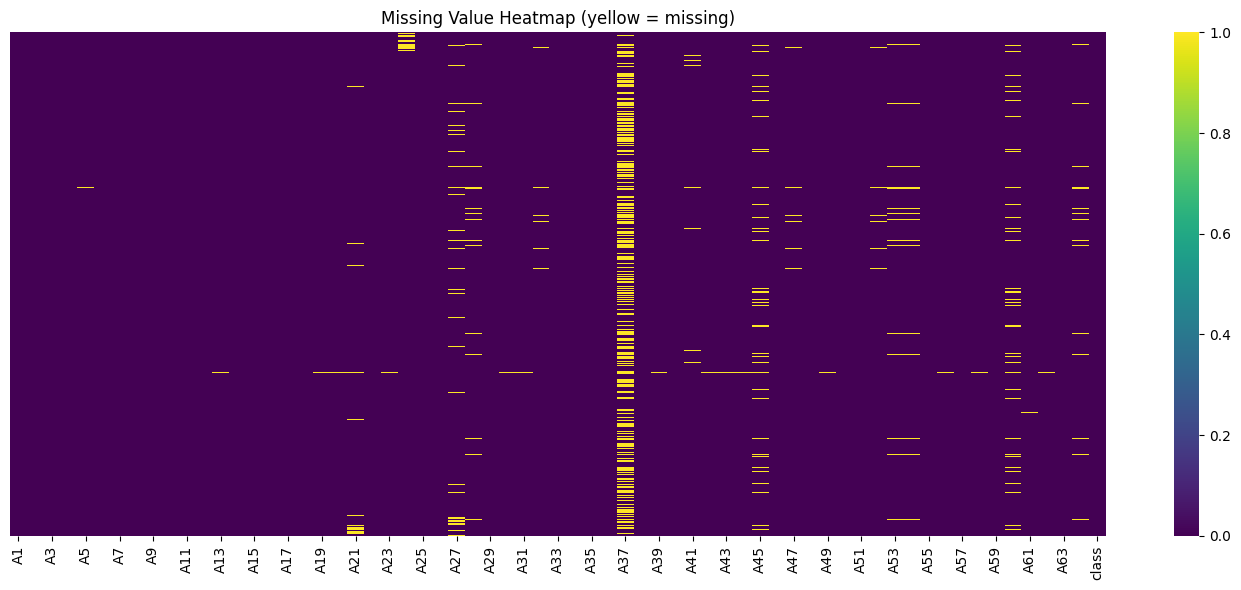

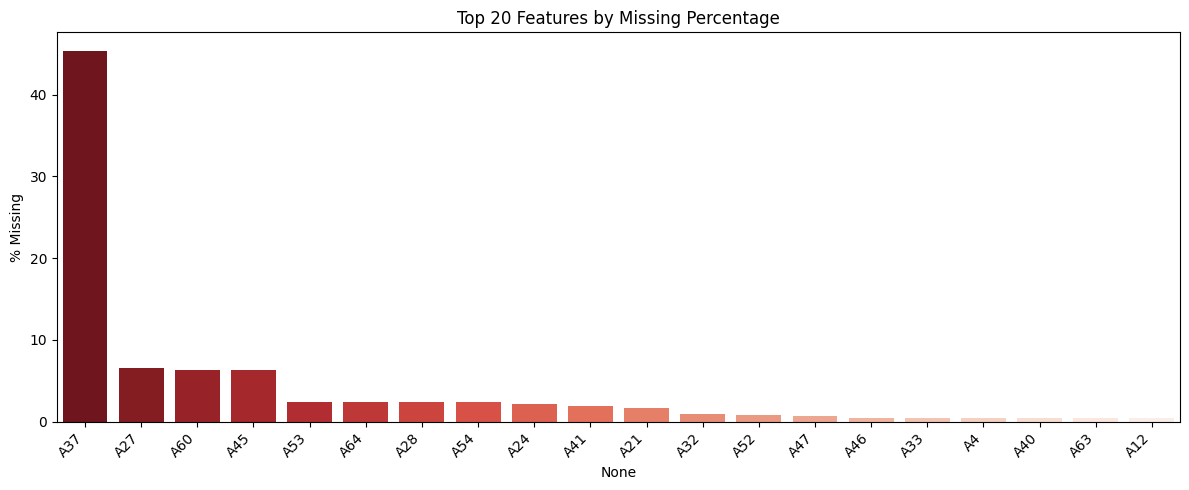

In [3]:
# ============================================================
# 2. DETAILED MISSINGNESS ANALYSIS
# ============================================================
print("\n" + "="*70)
print("MISSINGNESS ANALYSIS")
print("="*70)

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
}).sort_values('missing_pct', ascending=False)

print("\nColumns with missing values (sorted by % missing):")
print(missing_df[missing_df['missing_count'] > 0].to_string())

print(f"\nTotal missing cells: {missing.sum()}")
print(f"Columns with any missing: {(missing > 0).sum()} / {len(df.columns)}")
print(f"Rows with any missing: {df.isnull().any(axis=1).sum()} / {len(df)} "
      f"({df.isnull().any(axis=1).mean()*100:.1f}%)")

# Missingness by class
print("\nMissingness rate by class (top 10 features with missing):")
missing_by_class = df.groupby('class').apply(lambda x: x.isnull().mean()).T
missing_by_class.columns = ['class_0', 'class_1']
missing_by_class['diff'] = (missing_by_class['class_1'] - missing_by_class['class_0']).abs()
print(missing_by_class[missing_by_class['class_0'] + missing_by_class['class_1'] > 0]
      .sort_values('diff', ascending=False).head(10).round(3))

# Visualization: missingness heatmap (sample if too large)
plt.figure(figsize=(14, 6))
sns.heatmap(df.isnull(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Missing Value Heatmap (yellow = missing)')
plt.tight_layout()
plt.show()

# Bar plot of missing %
plt.figure(figsize=(12, 5))
top_missing = missing_df[missing_df['missing_pct'] > 0].head(20)
sns.barplot(x=top_missing.index, y=top_missing['missing_pct'], palette='Reds_r')
plt.xticks(rotation=45, ha='right')
plt.ylabel('% Missing')
plt.title('Top 20 Features by Missing Percentage')
plt.tight_layout()
plt.show()




SUMMARY STATISTICS
        count       mean          std           min          1%         5%       25%       50%        75%         95%          99%           max
A1     9791.0     0.0430       0.3593 -1.245800e+01     -0.5992    -0.2130    0.0013    0.0414     0.1111      0.2927       0.5603  2.048200e+01
A2     9791.0     0.5964       4.5871  0.000000e+00      0.0154     0.0718    0.2631    0.4677     0.6893      1.0704       2.4788  4.469100e+02
A3     9791.0     0.1310       4.5591 -4.459100e+02     -1.2864    -0.3548    0.0204    0.1993     0.4107      0.7272       0.9167  2.276900e+01
A4     9749.0     8.1366     290.6473 -4.530000e-02      0.1465     0.4750    1.0470    1.5918     2.8804      9.8145      44.1612  2.714600e+04
A5     9771.0    64.2556   14732.2695 -3.790000e+05  -3471.6600  -347.5100  -51.2170   -0.0556    55.7320    395.2050    3174.5300  1.030000e+06
A6     9791.0    -0.0593       6.8128 -4.868200e+02     -2.2550    -0.5447   -0.0006    0.0000     0.0653     

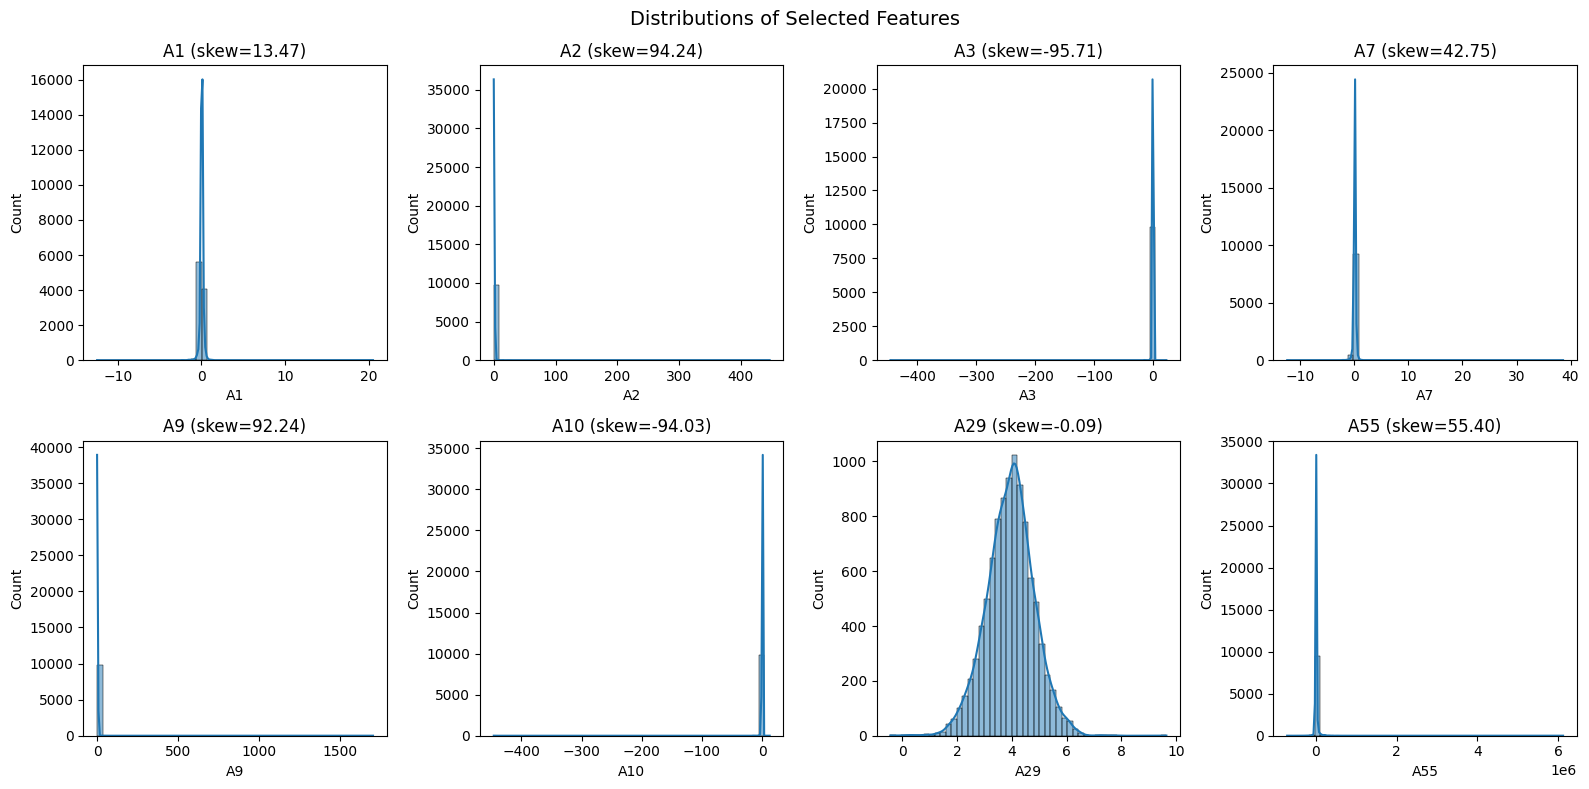

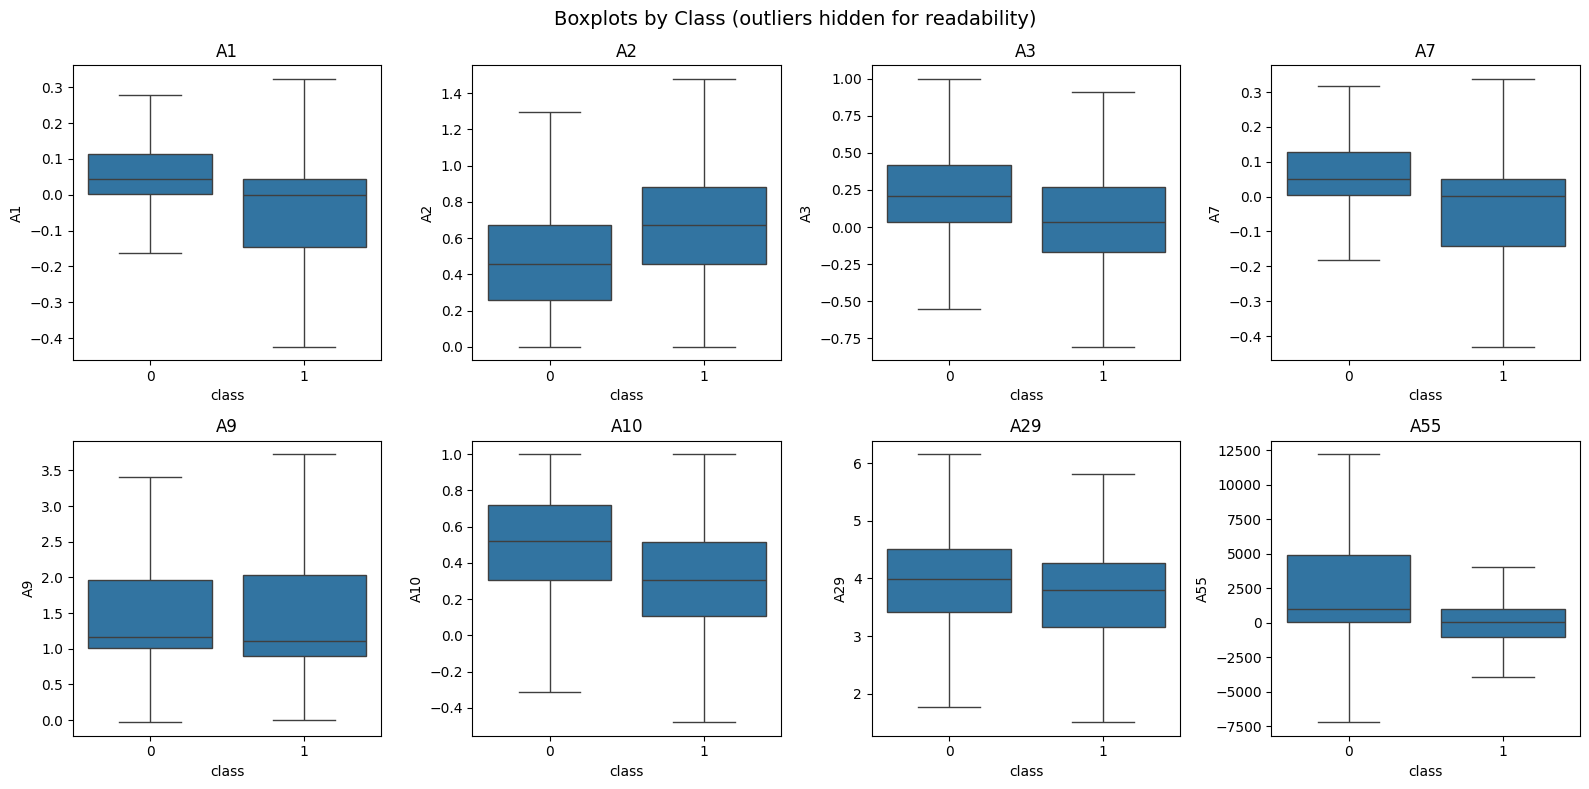

In [9]:
# ============================================================
# 3. SUMMARY STATISTICS & DISTRIBUTIONS
# ============================================================
print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

# Overall describe
desc = df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
print(desc.round(4).to_string())

# Separate by class
print("\n--- Mean of features by class (first 15) ---")
means_by_class = df.groupby('class').mean().T
print(means_by_class.head(15).round(4))

# Median comparison by class (robust to extreme financial ratios)
print("\n--- Median of selected financial ratios by class ---")
median_features = ['A1', 'A2', 'A3', 'A7', 'A10', 'A29']
class_medians = df.groupby('class')[median_features].median().T
class_medians = class_medians.rename(columns={0: 'Non-bankrupt', 1: 'Bankrupt'})
class_medians['Difference (bankrupt - non-bankrupt)'] = (
    class_medians['Bankrupt'] - class_medians['Non-bankrupt']
)
print(class_medians.round(4).to_string())

# Skewness & Kurtosis
skew_kurt = pd.DataFrame({
    'skewness': df.drop(columns='class').skew(),
    'kurtosis': df.drop(columns='class').kurtosis()
}).sort_values('skewness', key=abs, ascending=False)
print("\nMost skewed features (top 15):")
print(skew_kurt.head(15).round(3))

# Distribution plots for a selection of key features
key_feats = ['A1', 'A2', 'A3', 'A7', 'A9', 'A10', 'A29', 'A55']  # common bankruptcy ratios + log assets
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for i, col in enumerate(key_feats):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=50)
    axes[i].set_title(f'{col} (skew={df[col].skew():.2f})')
plt.suptitle('Distributions of Selected Features', fontsize=14)
plt.tight_layout()
plt.show()

# Boxplots by class for key features
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for i, col in enumerate(key_feats):
    sns.boxplot(x='class', y=col, data=df, ax=axes[i], showfliers=False)  # hide extreme outliers for visibility
    axes[i].set_title(col)
plt.suptitle('Boxplots by Class (outliers hidden for readability)', fontsize=14)
plt.tight_layout()
plt.show()





OUTLIER ANALYSIS (IQR method)
Features with highest % of IQR outliers:
     n_outliers  pct_outliers
A6         3186         32.54
A27        1993         20.35
A55        1704         17.40
A45        1650         16.85
A59        1620         16.54
A41        1601         16.35
A15        1592         16.26
A5         1491         15.23
A23        1462         14.93
A54        1421         14.51
A53        1392         14.22
A28        1390         14.20
A49        1358         13.87
A57        1355         13.84
A19        1354         13.83
A56        1352         13.81
A39        1342         13.71
A12        1333         13.61
A31        1330         13.58
A58        1312         13.40

Extreme outliers (|z-score| > 5):
A48    32
A37    27
A55    24
A1     23
A15    20
A53    18
A5     17
A22    15
A32    15
A57    15
A64    15
A35    14
A20    14
A28    14
A27    14
dtype: int64


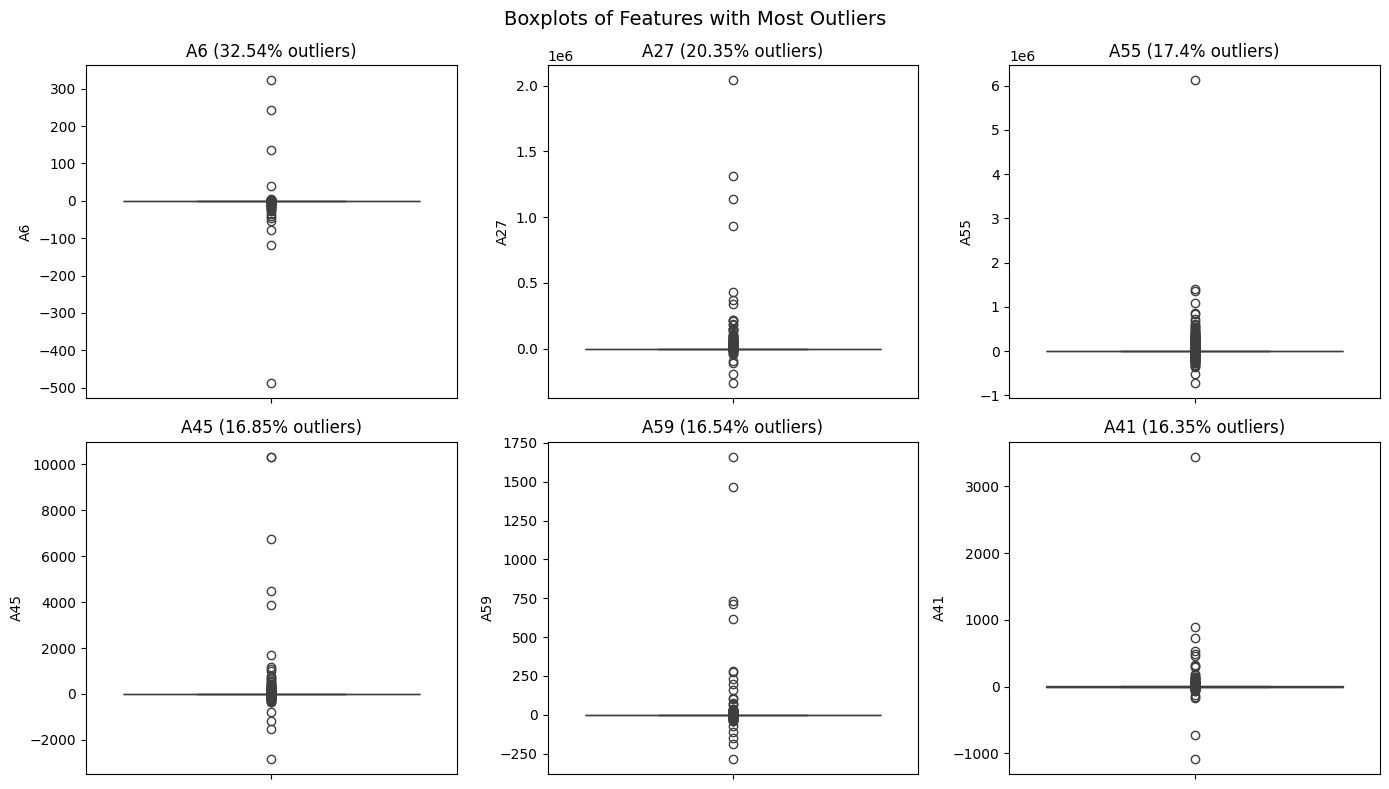

In [5]:
# ============================================================
# 4. OUTLIER ANALYSIS
# ============================================================
print("\n" + "="*70)
print("OUTLIER ANALYSIS (IQR method)")
print("="*70)

def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outlier_counts = df.drop(columns='class').apply(iqr_outliers)
outlier_pct = (outlier_counts / len(df) * 100).round(2)
outlier_df = pd.DataFrame({
    'n_outliers': outlier_counts,
    'pct_outliers': outlier_pct
}).sort_values('pct_outliers', ascending=False)

print("Features with highest % of IQR outliers:")
print(outlier_df.head(20).to_string())

# Z-score extreme outliers (|z| > 5)
print("\nExtreme outliers (|z-score| > 5):")
z_outliers = {}
for col in df.drop(columns='class').columns:
    z = np.abs(stats.zscore(df[col].dropna()))
    z_outliers[col] = (z > 5).sum()
z_df = pd.Series(z_outliers).sort_values(ascending=False)
print(z_df[z_df > 0].head(15))

# Visual: boxplot of a few high-outlier features
high_out_feats = outlier_df.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, col in enumerate(high_out_feats):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f'{col} ({outlier_df.loc[col, "pct_outliers"]}% outliers)')
plt.suptitle('Boxplots of Features with Most Outliers', fontsize=14)
plt.tight_layout()
plt.show()



CORRELATION ANALYSIS


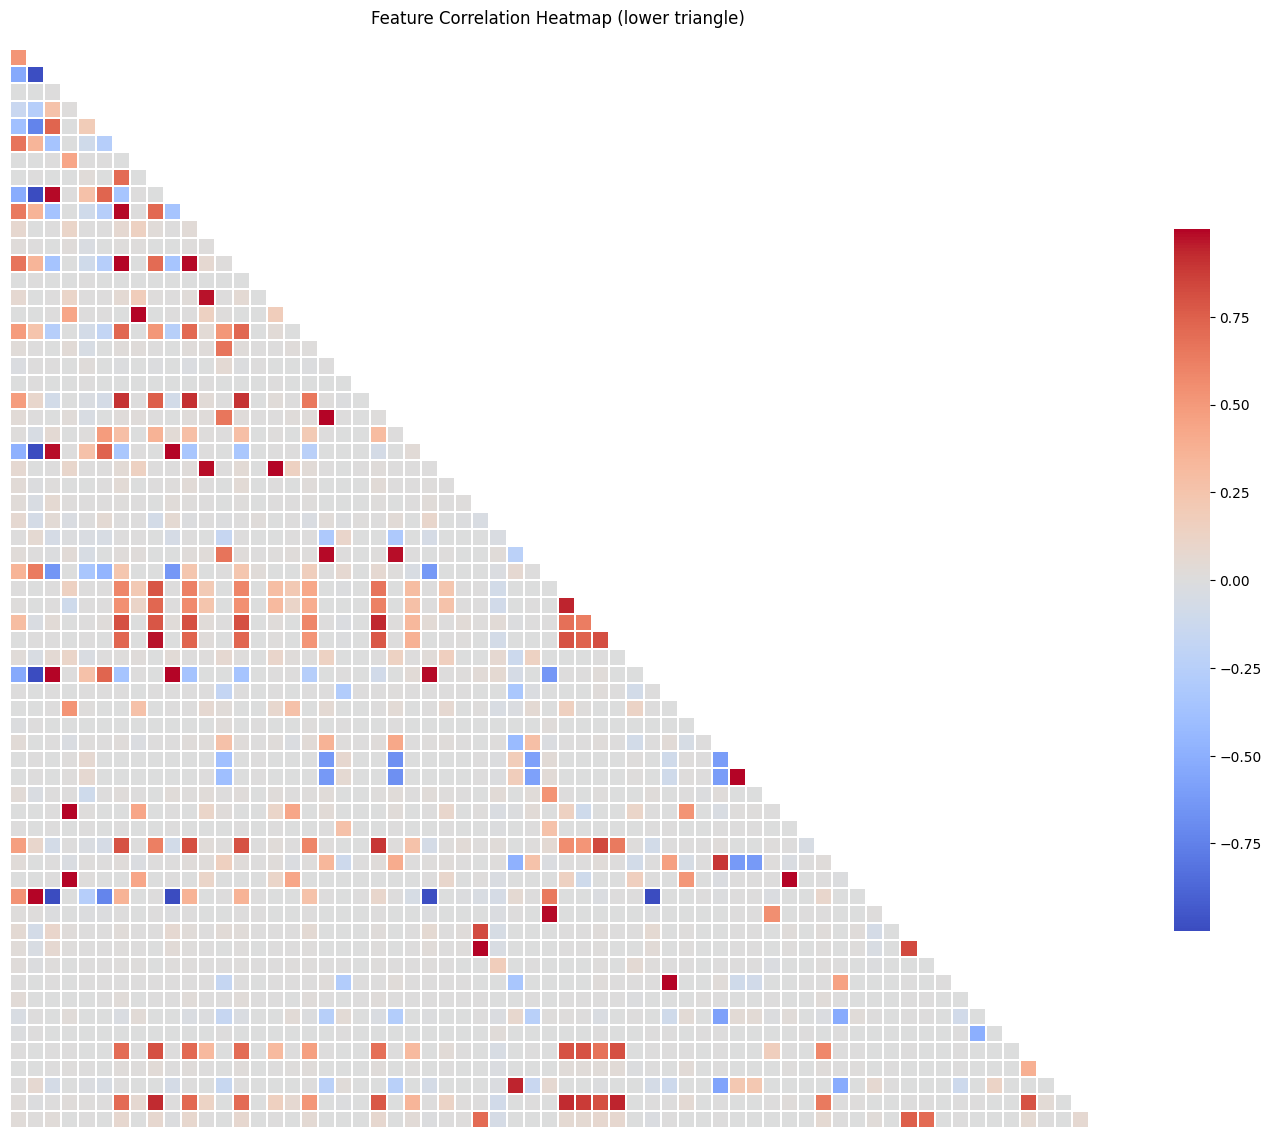


Top 20 highest absolute correlations (unique feature pairs):
         pearson_r  abs_pearson_r
A8  A17     1.0000         1.0000
A7  A14     1.0000         1.0000
A4  A46     0.9999         0.9999
A43 A44     0.9999         0.9999
A39 A56     0.9993         0.9993
A2  A10    -0.9993         0.9993
A28 A54     0.9987         0.9987
A3  A51    -0.9972         0.9972
A10 A38     0.9969         0.9969
A2  A38    -0.9962         0.9962
A16 A26     0.9950         0.9950
A19 A23     0.9947         0.9947
A38 A51    -0.9947         0.9947
A4  A50     0.9946         0.9946
A46 A50     0.9946         0.9946
A10 A25     0.9940         0.9940
A2  A25    -0.9935         0.9935
A3  A38     0.9934         0.9934
A2  A51     0.9923         0.9923
A10 A51    -0.9916         0.9916

Pearson vs Spearman for the top correlated pairs:
         pearson_r  spearman_r
A8  A17     1.0000      0.9955
A7  A14     1.0000      0.9998
A4  A46     0.9999      0.8929
A43 A44     0.9999      0.7091
A39 A56     0.9993

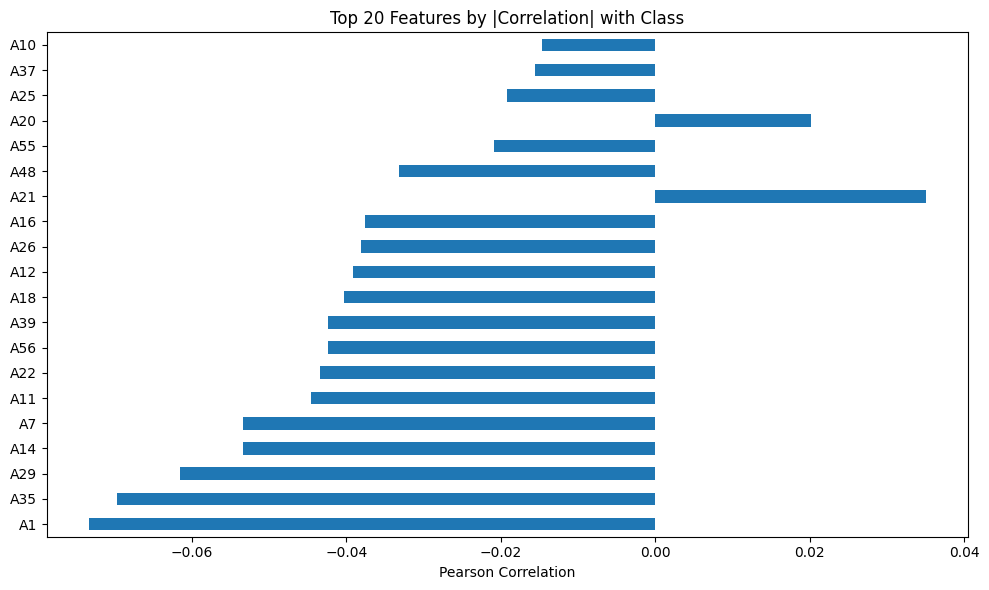

In [8]:
# ============================================================
# 5. CORRELATION ANALYSIS
# ============================================================
print("\n" + "="*70)
print("CORRELATION ANALYSIS")
print("="*70)

# Full correlation matrix (can be slow / large)
corr = df.drop(columns='class').corr()

# Heatmap of absolute correlations (top correlated pairs)
plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.6},
            xticklabels=False, yticklabels=False)
plt.title('Feature Correlation Heatmap (lower triangle)')
plt.tight_layout()
plt.show()

# Top absolute correlations: unique pairs from upper triangle,
# including correlations equal to +/-1 and retaining their signs.
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
corr_pairs = upper.stack().rename('pearson_r').to_frame()
corr_pairs['abs_pearson_r'] = corr_pairs['pearson_r'].abs()
corr_pairs = corr_pairs.sort_values('abs_pearson_r', ascending=False).head(20)
print("\nTop 20 highest absolute correlations (unique feature pairs):")
print(corr_pairs.round(4).to_string())

# Check whether the same pairs remain highly correlated by rank,
# which is less sensitive to extreme values.
spearman_corr = df.drop(columns='class').corr(method='spearman')
pair_check = corr_pairs[['pearson_r']].copy()
pair_check['spearman_r'] = [
    spearman_corr.loc[a, b] for a, b in pair_check.index
]
print("\nPearson vs Spearman for the top correlated pairs:")
print(pair_check.round(4).to_string())


# Correlation with target
target_corr = df.corr()['class'].drop('class').sort_values(key=abs, ascending=False)
print("\nFeatures most correlated with target (class):")
print(target_corr.head(20).round(4))

plt.figure(figsize=(10, 6))
target_corr.head(20).plot(kind='barh')
plt.title('Top 20 Features by |Correlation| with Class')
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.show()




ADDITIONAL DIAGNOSTICS

Features with very low cardinality (< 10 unique values):
class    2
dtype: int64

Infinite values present? False


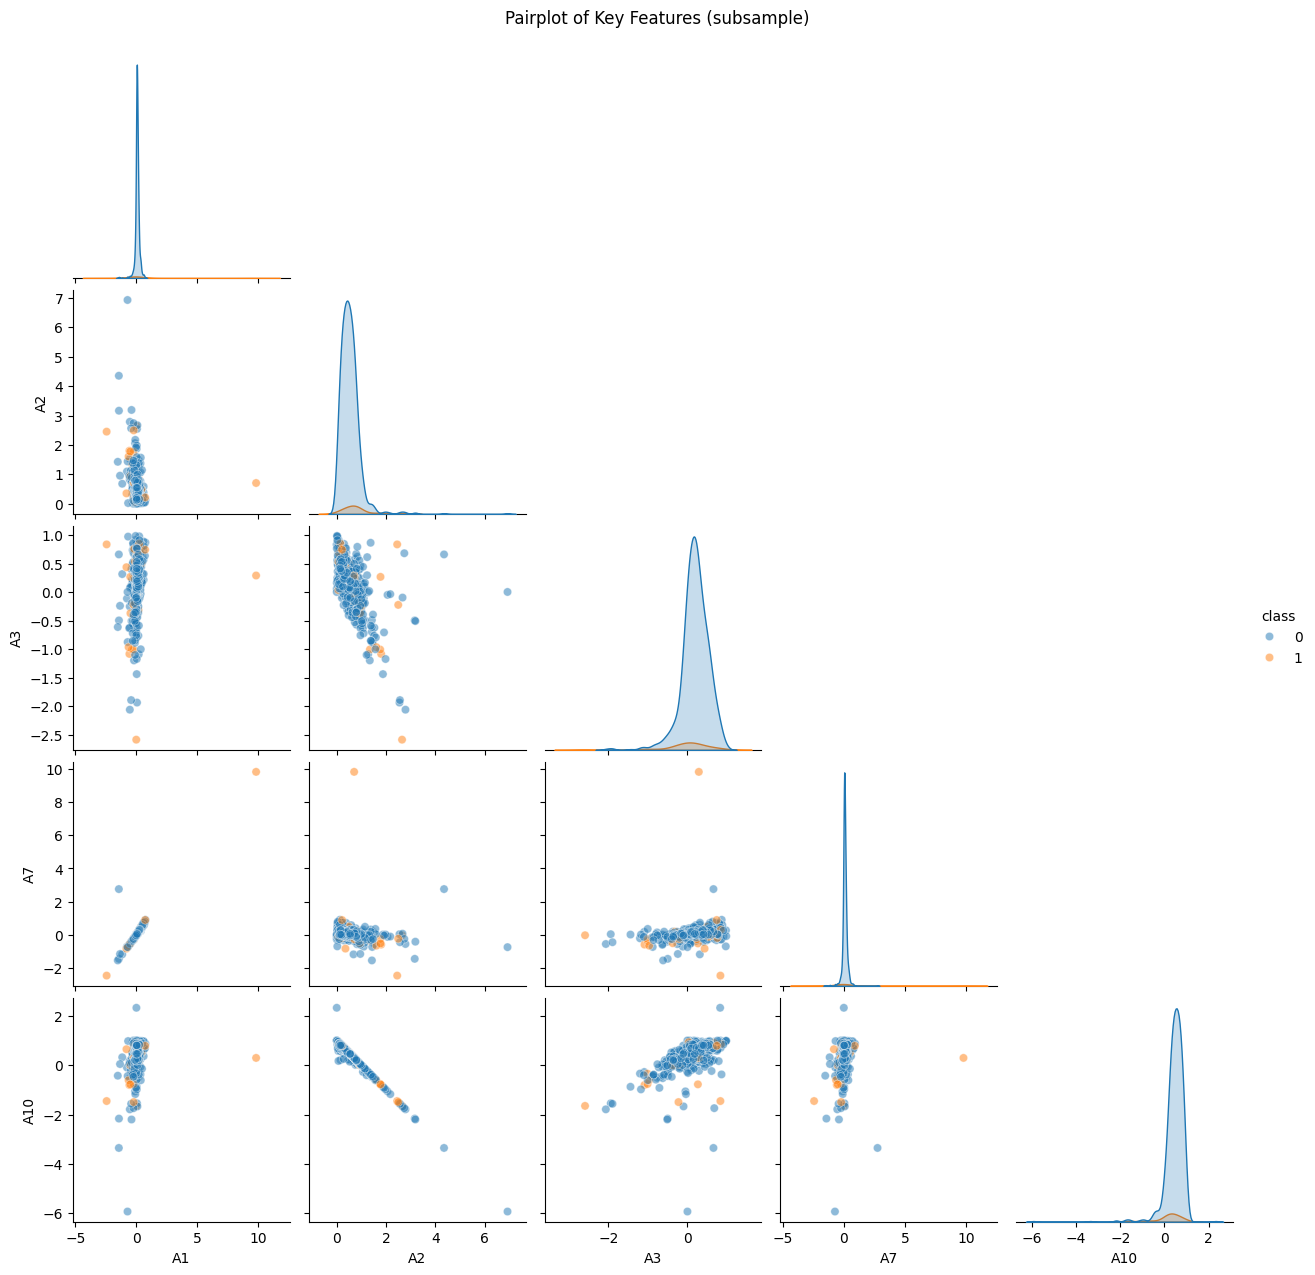


Missingness correlation (top pairs that are missing together):
A60  A45    0.997
A52  A47    0.980
     A32    0.889
A39  A58    0.873
A47  A32    0.871
A50  A33    0.664
A15  A50    0.567
A5   A47    0.509
     A52    0.499
     A32    0.466
dtype: float64

EDA COMPLETE


In [7]:
#============================================================
# 6. ADDITIONAL USEFUL EDA
# ============================================================
print("\n" + "="*70)
print("ADDITIONAL DIAGNOSTICS")
print("="*70)

# Constant / near-constant features
nunique = df.nunique()
print("\nFeatures with very low cardinality (< 10 unique values):")
print(nunique[nunique < 10])

# Infinite / extreme values check
print("\nInfinite values present?", np.isinf(df.select_dtypes(include=np.number)).any().any())

# Pairplot of a few important features (subsample for speed)
sample = df.sample(min(1000, len(df)), random_state=42)
sns.pairplot(sample[['A1', 'A2', 'A3', 'A7', 'A10', 'class']],
             hue='class', diag_kind='kde', corner=True, plot_kws={'alpha': 0.5})
plt.suptitle('Pairplot of Key Features (subsample)', y=1.02)
plt.show()

# Missingness pattern: which columns tend to be missing together?
print("\nMissingness correlation (top pairs that are missing together):")
miss_corr = df.isnull().astype(int).corr()
miss_pairs = miss_corr.unstack().sort_values(ascending=False)
miss_pairs = miss_pairs[(miss_pairs < 1) & (miss_pairs > 0.3)].drop_duplicates().head(10)
print(miss_pairs.round(3))

print("\n" + "="*70)
print("EDA COMPLETE")
print("="*70)

## EDA Summary and Modeling Implications

The two-year bankruptcy dataset contains **9,792 observations**, **64 financial-ratio predictors**, and **515 bankruptcies (5.26%)**. This imbalance means that a classifier predicting every company as non-bankrupt would achieve high accuracy while failing to detect any bankruptcies.

The EDA identified four considerations for model development:

1. **Missing values and informative missingness.** A37 is missing in **45.36%** of observations, making it a candidate for a retain-versus-drop comparison. Missingness also differs substantially by outcome: A27 is missing for **29.9% of bankrupt** versus **5.2% of non-bankrupt** observations, and A21 for **21.9% versus 0.5%**, respectively. These associations suggest that missingness indicators may carry predictive information, although they do not establish why the values are absent. A45 and A60 have nearly identical missingness patterns (indicator correlation approximately **0.997**). Model development will compare median imputation alone against median imputation with missingness indicators; A37 exclusion will be evaluated separately.

2. **Extreme and skewed financial ratios.** The IQR rule flags many observations for certain variables, including **A6 (32.54%)** and **A27 (20.35%)**. These are not necessarily data errors: extreme financial ratios may be meaningful for distressed companies. Rows will not be removed solely because they fall outside IQR fences. For scale-sensitive algorithms such as KNN and SVM, standard versus robust scaling will be compared within cross-validation.

3. **Correlated and potentially redundant predictors.** Some pairs have Pearson correlations near ±1, including **A8/A17** and **A7/A14**. Other pairs show substantial differences between Pearson and Spearman correlation (for example, **A43/A44: approximately 0.9999 versus 0.7091**), indicating that very high linear correlation does not always translate into equally strong rank association. Correlated features will not be dropped automatically; a feature-selection or reduced-feature experiment will test whether removing redundancy improves generalization.

4. **Weak individual linear associations with the target.** The largest absolute Pearson feature–target correlation observed was approximately **0.0734 (A1)**. This does not rule out nonlinear effects or interactions and supports comparing tree ensembles and other nonlinear classifiers against a simpler baseline.

### Modeling and validation plan

- Use an **80/20 stratified train/holdout split**, with **5-fold stratified cross-validation** on the training portion for model selection and hyperparameter tuning.
- Compare **logistic regression (baseline), KNN, decision tree, random forest, boosting, and SVM**, with an explanation of each model's suitability and limitations.
- Evaluate **average precision (PR-AUC), ROC-AUC, recall, precision, and F1**; report accuracy only as supporting context. Compare class weighting where available.
- Fit **imputation, missingness indicators, scaling, and feature selection inside training folds** to prevent leakage. Assess overfitting using training versus cross-validation results, and evaluate the selected approach once on the untouched holdout.
